# Preparing data for a machine learning model.

This notebook comes from the article [Preparing data for a machine learning model.](https://www.jeremyjordan.me/preparing-data-for-a-machine-learning-model/)

Dataset in Kagle: [Mental Health in Tech Survey](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey/data)

Article from: 30 May 2017. This is using a much older version of Pandas, so some of the code may not work with the current version. I will try to update it as I go along.

## Inspecting the data


In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("./data/week_2_survey.csv")
num_columns = len(df.columns)
pd.set_option("display.max_columns", num_columns)
df.head(30)

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN
5,2014-08-27 11:31:22,33,Male,United States,TN,NaN,Yes,No,Sometimes,6-25,No,Yes,Yes,Not sure,No,Don't know,Don't know,Don't know,No,No,Yes,Yes,No,Maybe,Don't know,No,NaN
6,2014-08-27 11:31:50,35,Female,United States,MI,NaN,Yes,Yes,Sometimes,1-5,Yes,Yes,No,No,No,No,No,Somewhat difficult,Maybe,Maybe,Some of them,No,No,No,Don't know,No,NaN
7,2014-08-27 11:32:05,39,M,Canada,NaN,NaN,No,No,Never,1-5,Yes,Yes,No,Yes,No,No,Yes,Don't know,No,No,No,No,No,No,No,No,NaN
8,2014-08-27 11:32:39,42,Female,United States,IL,NaN,Yes,Yes,Sometimes,100-500,No,Yes,Yes,Yes,No,No,No,Very difficult,Maybe,No,Yes,Yes,No,Maybe,No,No,NaN
9,2014-08-27 11:32:43,23,Male,Canada,NaN,NaN,No,No,Never,26-100,No,Yes,Don't know,No,Don't know,Don't know,Don't know,Don't know,No,No,Yes,Yes,Maybe,Maybe,Yes,No,NaN


The pandas `head()` function returns the first 5 rows of your dataframe by default, but I wanted to see a bit more to get a better idea of the dataset.

While we're at it, let's take a look at the shape of the dataframe too. Running `df.shape` will return information about the dimensionality of our dataframe (in this case it's the number of rows and columns), which will essentially tell you how many examples and features you are working with.

Pro tip: you can return the number of observations in your dataset with `df.shape[0]` and the number of features in your dataset with `df.shape[1]`. *This is often helpful to do when building a model.*

The first thing to understand is what features our dataset contains. You can read a description of each feature for this dataset on [Kaggle](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey).


## Dataset fields

- **`Timestamp`**
- **`Age`**
- **`Gender`**
- **`Country`**
- **`state`**: If you live in the United States, which state or territory do you live in?
- **`self_employed`**: Are you self-employed?
- **`family_history`**: Do you have a family history of mental illness?
- **`treatment`**: Have you sought treatment for a mental health condition?
- **`work_interfere`**: If you have a mental health condition, do you feel that it interferes with your work?
- **`no_employees`**: How many employees does your company or organization have?
- **`remote_work`**: Do you work remotely (outside of an office) at least 50% of the time?
- **`tech_company`**: Is your employer primarily a tech company/organization?
- **`benefits`**: Does your employer provide mental health benefits?
- **`care_options`**: Do you know the options for mental health care your employer provides?
- **`wellness_program`**: Has your employer ever discussed mental health as part of an employee wellness program?
- **`seek_help`**: Does your employer provide resources to learn more about mental health issues and how to seek help?
- **`anonymity`**: Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources?
- **`leave`**: How easy is it for you to take medical leave for a mental health condition?
- **`mental_health_consequence`**: Do you think that discussing a mental health issue with your employer would have negative consequences?
- **`phys_health_consequence`**: Do you think that discussing a physical health issue with your employer would have negative consequences?
- **`coworkers`**: Would you be willing to discuss a mental health issue with your coworkers?
- **`supervisor`**: Would you be willing to discuss a mental health issue with your direct supervisor(s)?
- **`mental_health_interview`**: Would you bring up a mental health issue with a potential employer in an interview?
- **`phys_health_interview`**: Would you bring up a physical health issue with a potential employer in an interview?
- **`mental_vs_physical`**: Do you feel that your employer takes mental health as seriously as physical health?
- **`obs_consequence`**: Have you heard of or observed negative consequences for coworkers with mental health conditions in your workplace?
- **`comments`**: Any additional notes or comments

Rather than inspecting each feature one-by-one, I opted for the lazier route and ran the following:

In [2]:
feature_names = df.columns.tolist()
feature_names.remove('Timestamp')
feature_names.remove('comments')

for i, column in enumerate(feature_names):
    if i > 0:
        print()
    print(column)
    print(df[column].value_counts(dropna=False))

Age
Age
 29             85
 32             82
 26             75
 27             71
 33             70
 28             68
 31             67
 34             65
 30             63
 25             61
 35             55
 23             51
 24             46
 37             43
 38             39
 36             37
 40             33
 39             33
 43             28
 22             21
 41             21
 42             20
 21             16
 45             12
 46             12
 44             11
 19              9
 18              7
 48              6
 50              6
 20              6
 51              5
 49              4
 56              4
 57              3
 54              3
 55              3
 47              2
 60              2
 99999999999     1
 5               1
-1               1
 11              1
 8               1
 61              1
 53              1
-29              1
-1726            1
 65              1
 62              1
 58              1
 329             1
 72 

This printed out a cell in my notebook with a ton of information about my dataset that I could easily consume by just scrolling through. As I looked through the dataset, I kept an eye out for things just as duplicate labels, erroneous or null values, and other things that just didn't quite seem right.

While many columns were fine as is, a couple columns needed cleaning. Here's a list of things I found that needed attention before feeding this model into a machine learning algorithm.

- The `Age`  column contained people who had not been born yet (negative numbers).
- The Age column also contained children (such as a 5 year old) that are unlikely to be taking a survey about their workplace.
- The Age column contained someone who is 99999999999 years old, they should be in the Guiness World Records book or something. Jokes aside, this value is erroneous.
- There are 49 different values listed for `Gender`. Moreso, "Male" and "male" are ostensibly the same but currently being treated as two distinct categories.
- `self_employed` and `work_interfere` contain some null values.

For numerical features, it can also be helpful to quickly examine any possible correlations between features. You can use the pandas scatter_matrix to easily visualize your data.

In [3]:
print(f"The dataframe has {df.shape[0]} rows and {df.shape[1]} columns")

The dataframe has 1259 rows and 27 columns


## Separate the features and labels

If we're using a supervised machine learning technique, we need to make a distinction in the data between features and labels for each observation. Ultimately, this depends on what you're looking to predict or classify. In this case, I've decided that I'd like to build a classifier to predict whether or not someone will seek treatment.

The code below separates the dataset into inputs and the answer I want the model to predict.

In [4]:
# DEPRECATED: features = df.drop('treatment', 1)
# The line below drops the treatment column from the dataframe and assigns it to the features variable
features = df.drop("treatment", axis=1)

# The line below assigns the treatment column from the dataframe to the labels variable
labels = df['treatment']

## Cleaning null values (missing data)

Let's start with figuring out what to do with the null values found in self_employed and work_interfere. In both of these cases, the column contains categorical data. This is important to note the distinction between treating null values for categorical and numerical data, as the treatment will depend on the type of data present.

There's not exactly a formulaic way to approach how to treat missing data, as the treatment largely depends on the context and the nature of the data. For example, are the data missing at random or is there a hidden relationship between missing data and some other predictor?

One option in dealing with missing data is to simply **ignore or remove** the rows in which data is missing, discarding them from our analysis. However, this method is often unpopular due to the loss of information - especially if there was a pattern in your missing data.

A more method for handling missing values is **imputation**, where we replace the null value with our best guess of what that value might be. Basic implementations will simply replace all missing values with the mean/median/mode of all of the values for the given feature. More advanced implementations will use other features in order to develop an estimator for your missing value.

Take the following example, which is a small dataset containing three features (weather condition, temperature, and humidity) to predict whether or not I am likely to play tennis.

| # | Weather | Temperature | Humidity | Play tennis? |
|---|---------|------------:|---------:|--------------|
| 1 | cloudy  | 60          | NaN      | yes          |
| 2 | rainy   | 75          | 80%      | NaN          |
| 3 | cloudy  | NaN         | 50%      | no           |
| 4 | sunny   | 65          | 40%      | yes          |

If we deleted all of the rows with null values we'd be left with one row, and our predictor would always guess that I would play tennis because that's the only example it has to learn from. Let's say we instead chose to replace the null temperature value in row 3 by mean imputation. In this case, row 3 temperature would be artificially reported to be 65. If we wanted to get fancier for replacing the null value for humidity in row 1, we could train an estimator to guess what the value might be given the weather and temperature data provided. **It's important to note that with data imputation you are artifically reducing the variation in your dataset by creating new values close to (or equal to) the mean.**

For a more in-depth analysis of techniques for treating missing data values, check out [this chapter](http://www.stat.columbia.edu/~gelman/arm/missing.pdf?ref=jeremyjordan.me) on missing-data imputation.

Scikit-learn provides an imputer implementation for dealing with missing data, as shown in the example below.

In [5]:
''' DEPRECATED
from sklearn.preprocessing import Imputer
imputer = Imputer(missing_values = 'NaN', strategy = 'mean', axis = 0)
'''
from sklearn.impute import SimpleImputer

numeric_cols = features.select_dtypes(include="number").columns
categorical_cols = features.select_dtypes(
    include=["object", "string", "category"]
).columns

features[numeric_cols] = SimpleImputer(
    strategy="mean",
    keep_empty_features=True,
).fit_transform(features[numeric_cols])

features[categorical_cols] = SimpleImputer(
    strategy="most_frequent",
    keep_empty_features=True,
).fit_transform(features[categorical_cols])

In [6]:
features

,Timestamp,Age,Gender,Country,state,self_employed,family_history,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37.0,Female,United States,IL,No,No,Often,6-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,* Small family business - YMMV.
1,2014-08-27 11:29:37,44.0,M,United States,IN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,* Small family business - YMMV.
2,2014-08-27 11:29:44,32.0,Male,Canada,CA,No,No,Rarely,6-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,* Small family business - YMMV.
3,2014-08-27 11:29:46,31.0,Male,United Kingdom,CA,No,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,* Small family business - YMMV.
4,2014-08-27 11:30:22,31.0,Male,United States,TX,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,* Small family business - YMMV.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1254,2015-09-12 11:17:21,26.0,male,United Kingdom,CA,No,No,Sometimes,26-100,No,Yes,No,No,No,No,Don't know,Somewhat easy,No,No,Some of them,Some of them,No,No,Don't know,No,* Small family business - YMMV.
1255,2015-09-26 01:07:35,32.0,Male,United States,IL,No,Yes,Often,26-100,Yes,Yes,Yes,Yes,No,No,Yes,Somewhat difficult,No,No,Some of them,Yes,No,No,Yes,No,* Small family business - YMMV.
1256,2015-11-07 12:36:58,34.0,male,United States,CA,No,Yes,Sometimes,More than 1000,No,Yes,Yes,Yes,No,No,Don't know,Somewhat difficult,Yes,Yes,No,No,No,No,No,No,* Small family business - YMMV.
1257,2015-11-30 21:25:06,46.0,f,United States,NC,No,No,Sometimes,100-500,Yes,Yes,No,Yes,No,No,Don't know,Don't know,Yes,No,No,No,No,No,No,No,* Small family business - YMMV.


## Finding duplicate names

I mentioned earlier that there were 49 different values for 'Gender' and I suspected that some of these values should not be treated as distinct categories. Ultimately, I decided to resegment the data into 3 categories: male, female, and other (which accounts for non-binary and transgendered persons).

If I wanted to build a preprocessing engine which could clean incoming data, I could have probably taken a fancier approach and used some clever regular expressions to recategorize this column. Alas, I opted for the quick and dirty approach.

In [7]:
male_terms = ["male", "m", "mal", "msle", "malr", "mail", "make", "cis male", "man", "maile", "male (cis)", "cis man"]

female_terms = ["female", "f", "woman", "femake", "femaile", "femake", "cis female", "cis-female/femme", "female (cis)", "femail", "cis woman"]

def clean_gender(response):
    if response.lower().rstrip() in male_terms:
        return "Male"
    elif response.lower().rstrip() in female_terms:
        return "Female"
    else:
        return "Other"

#df['Gender'] = df["Gender"].apply(lambda x: clean_gender(x))
# Apply the change on the features dataframe, not on the original one.
features['Gender'] = features["Gender"].apply(lambda x: clean_gender(x))

## Outlier detection

As I mentioned earlier, it seemed like there were some outlier values for Age which appear to be erroneous. Examples such as negative ages or extremely large integers could negatively affect the performance of our machine learning algorithm and we'll need to address them.

I went ahead and defined an acceptable range of ages for adults in the workplace and replaced numbers outside of this range with null values.

In [8]:
#df.Age.loc[(df.Age < 18) | (df.Age > 80)] = np.nan

# The line below removes the warning "You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy."
#df.loc[(df["Age"] < 18) | (df["Age"] > 80), "Age"] = np.nan
# Apply the change on the features dataframe, not on the original one.
features.loc[
    (features["Age"] < 18) | (features["Age"] > 80),
    "Age",
] = np.nan

These null values could then be treated using the sklearn Imputer described earlier.

After defining a working range, I wanted to visualize the distribution of ages present in this dataset.

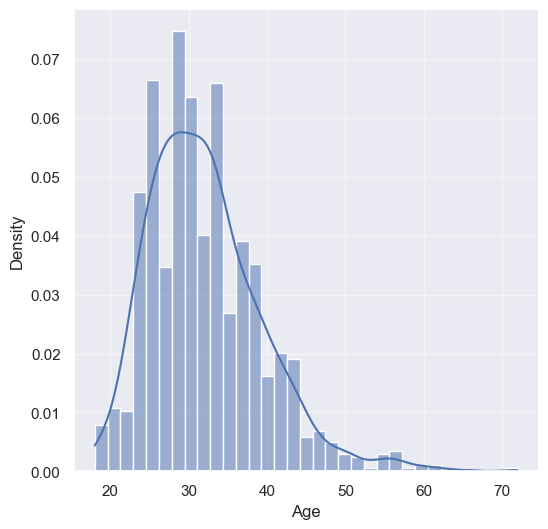

In [9]:
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt

''' DEPRECATED
sns.set(color_codes=True)
plot = sns.distplot(df.Age.dropna())
plot.figure.set_size_inches(6,6)
'''

sns.set_theme(color_codes=True)


plot = sns.histplot(
    data=features, # changed to 'features' as this is where I did the change.
    x="Age",
    stat="density",
    kde=True,
)
plot.figure.set_size_inches(6, 6)

If I want to compare the old dataframe, and the new dataframe where I have filtered ages less than  18 and  more than 80 to NaN.

Note: the following code will make the kernel crash with an out-of-memory error:

```python
import matplotlib.pyplot as plt

sns.set_theme(color_codes=True)

fig, ax = plt.subplots(figsize=(6, 6))

sns.histplot(
    data=df,
    x="Age",
    stat="density",
    kde=True,
    color="blue",
    alpha=0.3,
    label="Original df",
    ax=ax,
)

sns.histplot(
    data=features,
    x="Age",
    stat="density",
    kde=True,
    color="orange",
    alpha=0.3,
    label="Features df",
    ax=ax,
)

ax.set_title("Age: original vs processed")
ax.legend()
plt.show()
```
That is becuase the original `df` contains an extreme age of 99,999,999,999. Automatic histogram binning can try to allocate billions of bins across that range—likely causing the crash. My earlier code didn’t account for that.


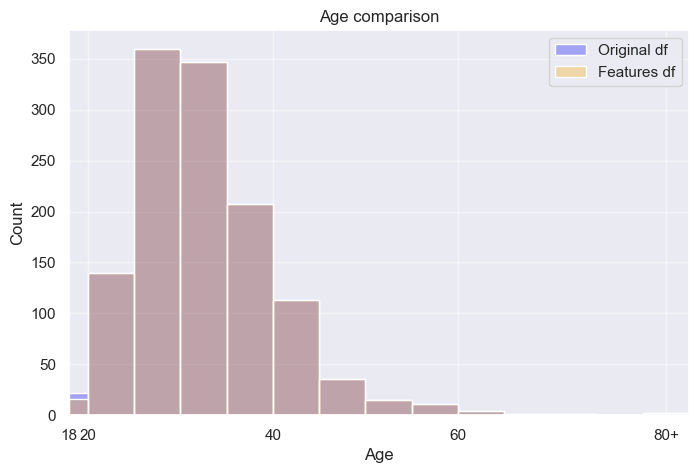

In [10]:
sns.set_theme(color_codes=True)

fig, ax = plt.subplots(figsize=(8, 5))
#bins = np.arange(0, 86, 5)
bins = np.r_[18, np.arange(20, 86, 5)]

for data, label, color in [
    (df, "Original df", "blue"),
    (features, "Features df", "orange"),
]:
    sns.histplot(
        x=data["Age"].clip(lower=18, upper=80),
        bins=bins,
        stat="count",
        kde=False,
        alpha=0.3,
        color=color,
        label=label,
        ax=ax,
    )

#ax.set_xticks([0, 20, 40, 60, 82.5])
#ax.set_xticklabels(["0", "20", "40", "60", "80+"])
ax.set_xlim(18, 85)
ax.set_xticks([18, 20, 40, 60, 82.5])
ax.set_xticklabels(["18", "20", "40", "60", "80+"])
ax.set(title="Age comparison", xlabel="Age", ylabel="Count")
ax.legend()
plt.show()

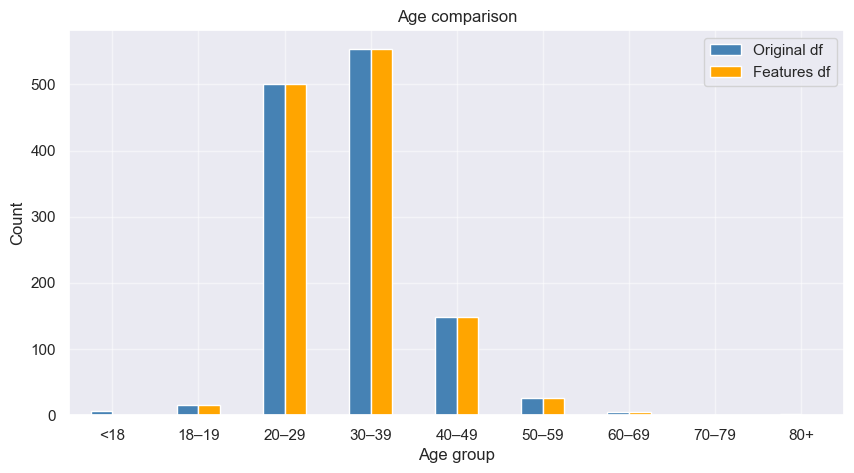

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

edges = [-np.inf, 18, 20, 30, 40, 50, 60, 70, 80, np.inf]
age_group_labels = [
    "<18", "18–19", "20–29", "30–39", "40–49",
    "50–59", "60–69", "70–79", "80+",
]

counts = pd.DataFrame({
    name: pd.cut(
        data["Age"], bins=edges, labels=age_group_labels, right=False
    ).value_counts(sort=False)
    for name, data in [("Original df", df), ("Features df", features)]
})

counts.plot.bar(ax=ax, color=["steelblue", "orange"], rot=0)
ax.set(title="Age comparison", xlabel="Age group", ylabel="Count")
plt.show()

In [12]:
print(f"The number of rows in the original dataframe whose age is less than 18 is {counts.loc['<18', 'Original df']}")

display(df[df['Age'] < 18])

print(f"The number of rows in the original dataframe whose age are 80+ is {counts.loc['80+', 'Original df']}")

display(df[df['Age'] > 80])

The number of rows in the original dataframe whose age is less than 18 is 6


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
143,2014-08-27 12:39:14,-29,Male,United States,MN,No,No,No,NaN,More than 1000,Yes,No,Yes,No,Don't know,Yes,Don't know,Don't know,No,No,Some of them,Yes,No,No,Don't know,No,NaN
715,2014-08-28 10:07:53,-1726,male,United Kingdom,NaN,No,No,Yes,Sometimes,26-100,No,No,No,No,No,No,Don't know,Somewhat difficult,Yes,No,No,No,No,Maybe,Don't know,No,NaN
734,2014-08-28 10:35:55,5,Male,United States,OH,No,No,No,NaN,100-500,No,Yes,Don't know,Not sure,No,No,Don't know,Somewhat easy,No,No,Yes,Yes,No,No,Yes,No,We had a developer suffer from depression and ...
989,2014-08-29 09:10:58,8,A little about you,"Bahamas, The",IL,Yes,Yes,Yes,Often,1-5,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Very easy,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,
1090,2014-08-29 17:26:15,11,male,United States,OH,Yes,No,No,Never,1-5,Yes,Yes,No,Yes,No,No,Yes,Very easy,No,No,Some of them,Some of them,No,Maybe,Yes,No,NaN
1127,2014-08-30 20:55:11,-1,p,United States,AL,Yes,Yes,Yes,Often,1-5,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Very easy,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,password: testered


The number of rows in the original dataframe whose age are 80+ is 2


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
364,2014-08-27 15:05:21,329,Male,United States,OH,No,No,Yes,Often,6-25,Yes,Yes,Yes,Yes,No,No,Don't know,Don't know,Maybe,No,Some of them,No,No,No,No,No,NaN
390,2014-08-27 15:24:47,99999999999,All,Zimbabwe,NaN,Yes,Yes,Yes,Often,1-5,No,Yes,No,Yes,No,No,No,Very difficult,Yes,Yes,No,No,Yes,No,No,Yes,NaN


*Note: pandas has plotting capabilities built-in that you can use, but I'm a fan of [seaborn](https://seaborn.pydata.org/?ref=jeremyjordan.me) and wanted to show that you have options when it comes to visualizing data.*

Alright, at this point is seems like we're working with a pretty clean dataset. However, we're still not ready to pass our data into a machine learning model.

## Encoding data

Many machine learning algorithms expect numerical input data, so we need to figure out a way to represent our categorical data in a numerical fashion.

One solution to this would be to arbitrarily assign a numerical value for each category and map the dataset from the original categories to each corresponding number. For example, let's look at the 'leave' column (How easy is it for you to take medical leave for a mental health condition?) in our dataset

Reference: [pandas.Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)

`Series.value_counts(normalize=False, sort=True, ascending=False, bins=None, dropna=True)`

 - normalize: bool, default False

    If True then the object returned will contain the relative frequencies of the unique values.
- sort: bool, default True

    Stable sort by frequencies when True. Preserve the order of the data when False.
    Changed in version 3.0.0: Prior to 3.0.0, the sort was unstable.
- ascending: bool, default False

    Sort in ascending order.
- bins: int, optional

    Rather than count values, group them into half-open bins, a convenience for pd.cut, only works with numeric data.
- **dropna**: bool, default True

    Don’t include counts of NaN.

In [13]:
df['leave'].value_counts(dropna=False)

leave
Don't know            563
Somewhat easy         266
Very easy             206
Somewhat difficult    126
Very difficult         98
Name: count, dtype: int64

In order to encode this data, we could map each value to a number.

In [14]:
df['ordered_leave'] = df['leave'].map({'Very difficult': 0, 'Somewhat difficult': 1, 'Don\'t know': 2, 'Somewhat easy': 3, 'Very easy': 4})

This process is known as label encoding, and sklearn conveniently will do this for you.

In [15]:
from sklearn import preprocessing
label_encoder = preprocessing.LabelEncoder()
#label_encoder.fit(df['leave'])
#label_encoder.transform(df['leave'])
df["encoded_leave"] = label_encoder.fit_transform(df["leave"])

In [16]:
display(
    df[["leave", "ordered_leave", "encoded_leave"]]
    .drop_duplicates()
    .sort_values("ordered_leave")
    .reset_index(drop=True)
)

,leave,ordered_leave,encoded_leave
0,Very difficult,0,3
1,Somewhat difficult,1,1
2,Don't know,2,0
3,Somewhat easy,3,2
4,Very easy,4,4


The problem with this approach is that you're introducing an order that might not be present. In this case, one could argue that the data is ordinal ("very difficult" is less than "somewhat difficult" which is less than "somewhat easy" which is less than "very easy") but many times categorical data has no order. For example, if you had a feature for animal species, it doesn't make sense to assign values such than cats are less than dogs. The danger in label encoding is that your machine learning algorithm may learn to favor dogs over cats due to artficial ordinal values you introduced during encoding.

The common solution for encoding nominal data is one-hot encoding.

Rather than replacing the categorical value with a numerical value (**label encoding**) as shown below:

| # | Species | Numerical encoding |
|---|---------|-------------------:|
| 1 | cat     | 1                  |
| 2 | dog     | 2                  |
| 3 | snake   | 3                  |
| 4 | cat     | 1                  |
| 5 | dog     | 2                  |
| 6 | turtle  | 4                  |
| 7 | dog     | 2                  |

We instead create a column for each category and use 1s and 0s to indicate whether it is present. These new columns are often referred to as **dummy variables**.

| # | Species | is_cat | is_dog | is_snake | is_turtle |
|---|---------|-------:|-------:|---------:|----------:|
| 1 | cat     | 1      | 0      | 0        | 0         |
| 2 | dog     | 0      | 1      | 0        | 0         |
| 3 | snake   | 0      | 0      | 1        | 0         |
| 4 | cat     | 1      | 0      | 0        | 0         |
| 5 | dog     | 0      | 1      | 0        | 0         |
| 6 | turtle  | 0      | 0      | 0        | 1         |
| 7 | dog     | 0      | 1      | 0        | 0         |

You can one-hot encoding in directly in Pandas or use sklearn, although sklearn is a bit more convulted as the one-hot encoder only works for integer value inputs. For our example (where the inputs are strings), we would need to first perform label encoding and then one-hot encode the data.

In [17]:
# Using Pandas
import pandas as pd
#pd.get_dummies(features['leave'])

dummies_df = pd.get_dummies(
    features["leave"],
    prefix="leave",
    dtype=int,
)

dummies_df

,leave_Don't know,leave_Somewhat difficult,leave_Somewhat easy,leave_Very difficult,leave_Very easy
0,0,0,1,0,0
1,1,0,0,0,0
2,0,1,0,0,0
3,0,1,0,0,0
4,1,0,0,0,0
...,...,...,...,...,...
1254,0,0,1,0,0
1255,0,1,0,0,0
1256,0,1,0,0,0
1257,1,0,0,0,0


In [18]:
'''DEPRECATED
# Using sklearn
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
label_encoder = LabelEncoder()
ohe = OneHotEncoder(categorical_features = ['leave'])
label_encoded_data = label_encoder.fit_transform(features['leave'])
ohe.fit_transform(label_encoded_data.reshape(-1,1))
'''

from sklearn.preprocessing import OneHotEncoder

# Configure the one-hot encoder.
ohe = OneHotEncoder(
    sparse_output=False,      # Return a regular NumPy array.
    handle_unknown="ignore",  # Unseen categories during later transforms
                              # produce zeros in all leave columns.
    dtype=int,                # Store indicators as integers: 0 or 1.
)

# Learn the categories in "leave" and encode each row.
# Double brackets keep the input as a 2D DataFrame, as required.
encoded_leave = ohe.fit_transform(features[["leave"]])

# Convert the encoded array into a labelled DataFrame.
encoded_leave_df = pd.DataFrame(
    encoded_leave,
    # Generate names such as "leave_Very easy".
    columns=ohe.get_feature_names_out(["leave"]),
    # Preserve row indices so the result aligns with features.
    index=features.index,
)

# Show the first five encoded rows.
display(encoded_leave_df.head())

,leave_Don't know,leave_Somewhat difficult,leave_Somewhat easy,leave_Very difficult,leave_Very easy
0,0,0,1,0,0
1,1,0,0,0,0
2,0,1,0,0,0
3,0,1,0,0,0
4,1,0,0,0,0


Comparing both method:

In [19]:
'''display(
    pd.concat(
        {"get_dummies": dummies_df, "OneHotEncoder": encoded_leave_df},
        axis=1,
    ).head()
)'''

all_columns = dummies_df.columns.union(encoded_leave_df.columns)

different_columns = [
    col
    for col in all_columns
    if col not in dummies_df.columns
    or col not in encoded_leave_df.columns
    or not dummies_df[col].equals(encoded_leave_df[col])
]

print(f"Number of differing columns: {len(different_columns)}")
print("Differing columns:", different_columns)

if different_columns:
    display(
        pd.concat(
            {
                "get_dummies": dummies_df.reindex(columns=different_columns),
                "OneHotEncoder": encoded_leave_df.reindex(
                    columns=different_columns
                ),
            },
            axis=1,
        )
    )

Number of differing columns: 0
Differing columns: []


## Feature scaling

At this point, we've successfully cleaned our data and converted it into a form which is easily consumable by machine learning algorithms. However, at this point we should consider whether or not some method of data normalization will be beneficial for our algorithm. This depends on (1) the data, (2) what we're trying to learn, and (3) the algorithm we plan to implement. Sometimes you'll need to revisit this step if you decide to change your machine learning algorithm.

### The data

Suppose you have a dataset of features with different units: temperature in Kelvin, percent relative humidity, and day of year. If this dataset is representing weather values in Raleigh we might see the following ranges for each feature.

- Temperature: 270 K to 305 K
- Humidity: 0 to 1 (ie. 30% humidity represented by 0.3)
- Day of year: 0 to 365

When you're interpreting these values, you intuitively normalize values as you're thinking about them. For example, you recognize that an increase of 0.5 (remember: that's 50%) for humidity is much more drastic of a change than an increase of 0.5 Kelvin. However, if we don't scale these features our algorithm might learn to use temperature as the main predictor simply because its scale is largest (and thus changes in temperature values are most significant to the algorithm). **Feature scaling allows for all features to contribute equally (or more aptly, it allows for features to contribute relative to their importance rather than their scale).**

### What we're trying to learn

Sometimes, we'd like to be able to interpret our coefficients and changing the scale from something real (ie. dollars) to something arbitrary makes it more difficult to interpert our results.

### The algorithm

If you're using a tool such as gradient descent to optimize your algorithm, feature scaling allows for a consistent updating of weights across all dimensions.

The following sketchs are borrowed from Andrew Ng's slides on gradient descent. The first image represents two features with different scales while the latter represents a normalized feature space. The gradient descent optimization may take a long time to search for a local optimum as it goes back and forth along the contours. A normalized feature space allows for much quicker convergence.

![Gradient descent with different scales](images/reference/week_2_extra_gradient_descent_1.png)

![Gradient descent normalized](images/reference/week_2_extra_gradient_descent_2.png)

ML algorithms which require feature scaling:

- Logistic regression
- SVMs
- Perceptrons
- Neural networks
- PCA

ML algorithms which do not require feature scaling:

- Decision trees (and random forests)
- Naive Bayes

*Note: the above lists are by no means exhaustive but simply serve as an example.*

There's a few different methods for scaling features to a standardized range. Min-max scalers and standard scalers are two of the most commonly used approaches.

Min-max scaling sets your lowest observed value to 0 and your highest observed value to 1.

$${X_{sc}} = \frac{{X - {X_{\min }}}}{{{X_{\max }} - {X_{\min }}}}$$

Standard scaling will convert the data to have a standard normal distrubtion.

$$z = \frac{{X - \mu }}{\sigma }$$

To do this (feature scaling) in practice, you can use pre-built libraries in sklearn.

```python
# Feature scaling with StandardScaler
from sklearn.preprocessing import StandardScaler
scale_features_std = StandardScaler()
features_train = scale_features_std.fit_transform(features_train)
features_test = scale_features_std.transform(features_test)

# Feature scaling with MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
scale_features_mm = MinMaxScaler()
features_train = scale_features_mm.fit_transform(features_train)
features_test = scale_features_mm.transform(features_test)
```

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

numeric_features = features.select_dtypes(include="number")

features_train, features_test, labels_train, labels_test = train_test_split(
    #features, # This will throw an error because of the non-numeric features: "ValueError: could not convert string to float: '2014-08-28 12:22:14'"
    numeric_features,
    labels,
    test_size=0.25,       # 25% test, 75% training
    random_state=0,     # Reproducible split
    #stratify=labels,     # Preserve treatment class proportions
)

# Option 1: Standard scaling
scale_features_std = StandardScaler()
features_train_std = scale_features_std.fit_transform(features_train)
features_test_std = scale_features_std.transform(features_test)

# Option 2: Min-max scaling
scale_features_mm = MinMaxScaler()
features_train_mm = scale_features_mm.fit_transform(features_train)
features_test_mm = scale_features_mm.transform(features_test)


Plotting the results of the different scaling methods can help you visualize the differences between them. The following code will plot the distribution of the "Age" feature for the original data, the standard scaled data, and the min-max scaled data.

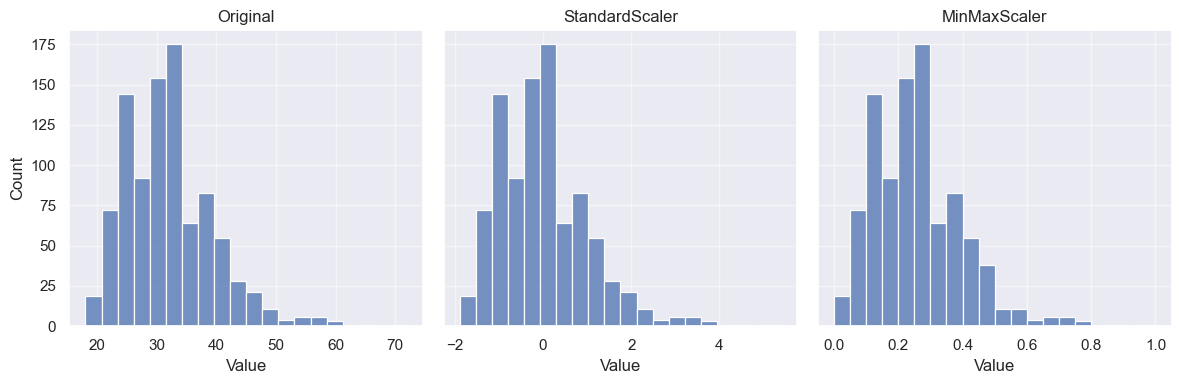

The first 10 columns with a 3 deciman rounding:


,Original,StandardScaler,MinMaxScaler
0,33.0,0.134,0.278
1,38.0,0.810,0.370
2,35.0,0.405,0.315
3,29.0,-0.406,0.204
4,31.0,-0.136,0.241
5,29.0,-0.406,0.204
6,31.0,-0.136,0.241
7,41.0,1.215,0.426
8,37.0,0.675,0.352
9,36.0,0.540,0.333



The min, mean, std, and max of each column:


,Original,StandardScaler,MinMaxScaler
min,18.000,-1.891,0.000
mean,32.004,-0.000,0.259
std,7.409,1.001,0.137
max,72.000,5.401,1.000


In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

column = "Age"
column_index = features_train.columns.get_loc(column)

comparison = pd.DataFrame({
    "Original": features_train[column].to_numpy(),
    "StandardScaler": features_train_std[:, column_index],
    "MinMaxScaler": features_train_mm[:, column_index],
})

plot_data = comparison.melt(
    var_name="Scaling",
    value_name="Value",
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True) # The sharey argument ensures that the Y axes are shared across all subplots.

# Not required: Only the scaled plots share X and Y axes.
#axes[2].sharex(axes[1])
#axes[2].sharey(axes[1])

for ax, scaling in zip(
    axes, ["Original", "StandardScaler", "MinMaxScaler"]
):
    sns.histplot(
        data=plot_data[plot_data["Scaling"] == scaling],
        x="Value",
        bins=20,
        ax=ax,
    )
    ax.set_title(scaling)

fig.tight_layout()
plt.show()

print("The first 10 columns with a 3 deciman rounding:")
display(comparison.head(10).round(3))
print("\nThe min, mean, std, and max of each column:")
display(comparison.agg(["min", "mean", "std", "max"]).round(3))

A few notes on this implementation:

- In practice, you may decide to only scale certain columns. For example, you don't need to scale the dummy variables from one-hot encoding.
- You'll want to scale your features the same for both the training and test sets (I'm getting ahead of myself here, stay tuned for the next section), so be sure to only transform the test set and not refit the scaler.
- I provided two ways to scale your feature set in the code above, choose one.

## Splitting the data for training and testing

One of the last things we'll need to do in order to prepare out data for a machine learning algorithm is to **split the data into training and testing subsets.** Remember, machine learning is all about teaching computers to perform a task by showing it a lot of examples. We'll teach the computer using the data we have available, but **ideally the algorithm will work just as well with new data. The principle behind the train/test split is to sacrifice some of the data for training in an attempt to evaluate the algorithm on "new" data it hasn't already seen. This is important because we want to ensure that our algorithm is able to generalize its learning from the given examples.**

A nice analogy I heard once relates the concept to studying for a test. Let's say we have two students who are preparing for the same test- one student makes an effort to understand the general concepts that will be tested while the other student simply memorizes every example from the relevant homework sets. If the test contains new problems that weren't on the homework but are still related to the concepts discussed, the former student will perform much better on the test than the student who memorized the homework answers. In machine learning, we use the term **overfitting** to describe whether or not an algorithm has read too much into the data we provided as examples, or whether it was capable of generalizing the concepts we were trying to teach it.

Let's go ahead and split the data into two subsets (really it's four subsets, since we already separated features from labels).

```python
from sklearn.model_selection import train_test_split
features_train, features_test, labels_train, labels_test = train_test_split(features, labels, test_size=0.25, random_state = 0)
```

*Note: this will also shuffle your data. This is important if your data is ordered.*

## Validation data

When constructing a machine learning model, we often split the data into three subsets: train, validation, and test subsets. The training data is used to "teach" the model, the validation data is used to [search for the best model architecture](https://www.jeremyjordan.me/hyper-parameter-tuning/), and the test data is reserved as an unbiased evaluator of our model. When building a model, we often are presented with choices regarding the model's overall design; **the validation data allows us to evaluate multiple designs in search of the best design, but in doing so we're "fitting" our model's design to this subset. Thus, the test data is still useful in determining how well our model will generalize what it learned to new data.**

For machine learning problems with limited data, it's desirable to maximize the amount of data used to actually train your model. However, you must still hold out sufficient data for the validation set to evaluate model performance. In such situations, K-folds cross validation may come in handy.

For K-folds cross validation, we partition the dataset into bins. We will then run different learning experiments, each time choosing one bin as the evaluation subset while using the rest to train our algorithm. We can then average the results from all of the experiments to get an accurate picture of it's performance, using the entire dataset (albeit not at the same time) to both train and test the performance of our algorithm. Obviously, this approach will take more time, but it will give a more accurate evaluation of our machine learning model.

![K-folds cross validation](./images/reference/week_2_extra_k_fold.png)

[Image credit](https://sebastianraschka.com/faq/docs/evaluate-a-model.html?ref=jeremyjordan.me)

### Verifying consistent distributions across subsets

You'll get the best results if you're training and evaluating your data on data that has a similar distribution. Thus, it's best to verify this when splitting your data into subsets.

## How much data is enough data?

Another useful thing to do at this stage is plot learning curves to judge whether or not you've collected sufficient data. These learning curves plot the training and validation scores of your algorithm for varying numbers of training examples.

![Learning curves](./images/reference/week_2_extra_learning_curve.png)

[Image credit](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html?ref=jeremyjordan.me)

You will see that your model will plateau at a certain point and you'll begin to experience diminishing returns from adding additional training examples. This is primarily useful as it will tell you that you either need to go collect more data or that you've collected sufficient data and you shouldn't spend more time growing your dataset. For supervised learning, it can often be expensive to collect and label additional data for use in your model.

*Note: this is where deep learning shines! Deep learning techniques are typically more capable of continuing to learn and improve the more data you feed it.*

An example of sklearn's learning curve implementation can be found [here](https://github.com/scikit-learn/scikit-learn/blob/master/examples/model_selection/plot_learning_curve.py?ref=jeremyjordan.me).

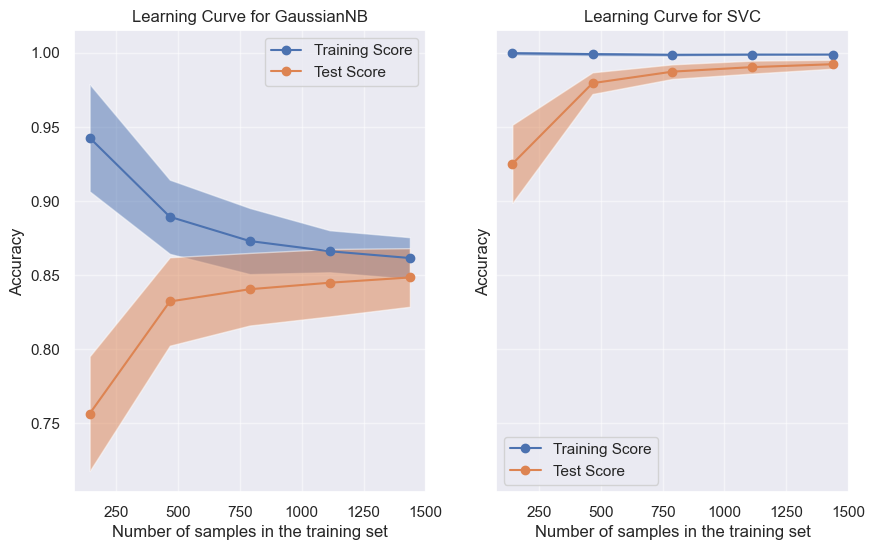

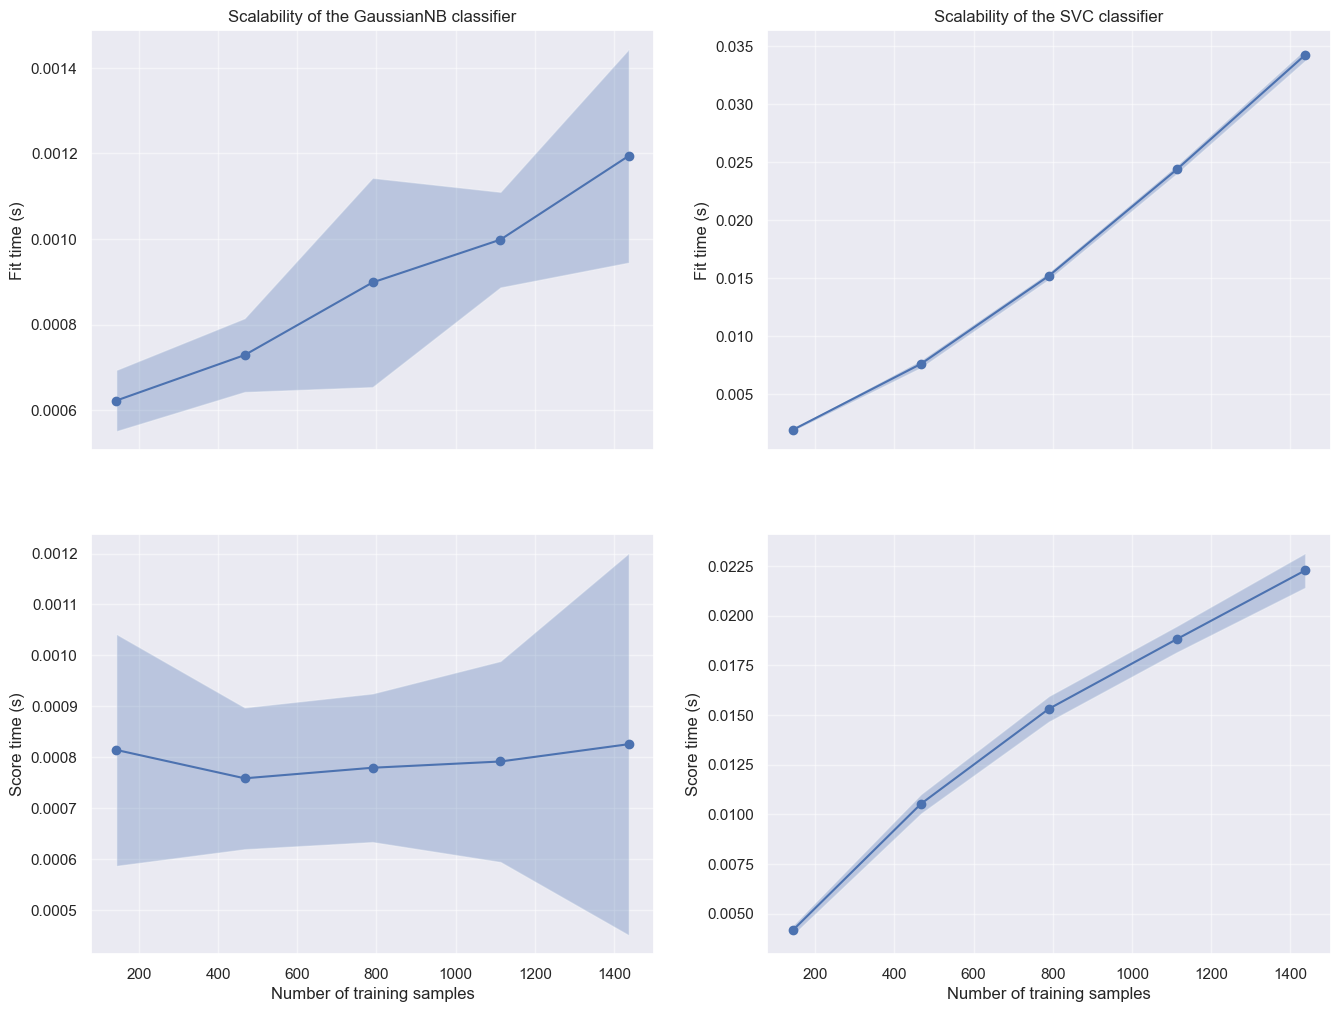

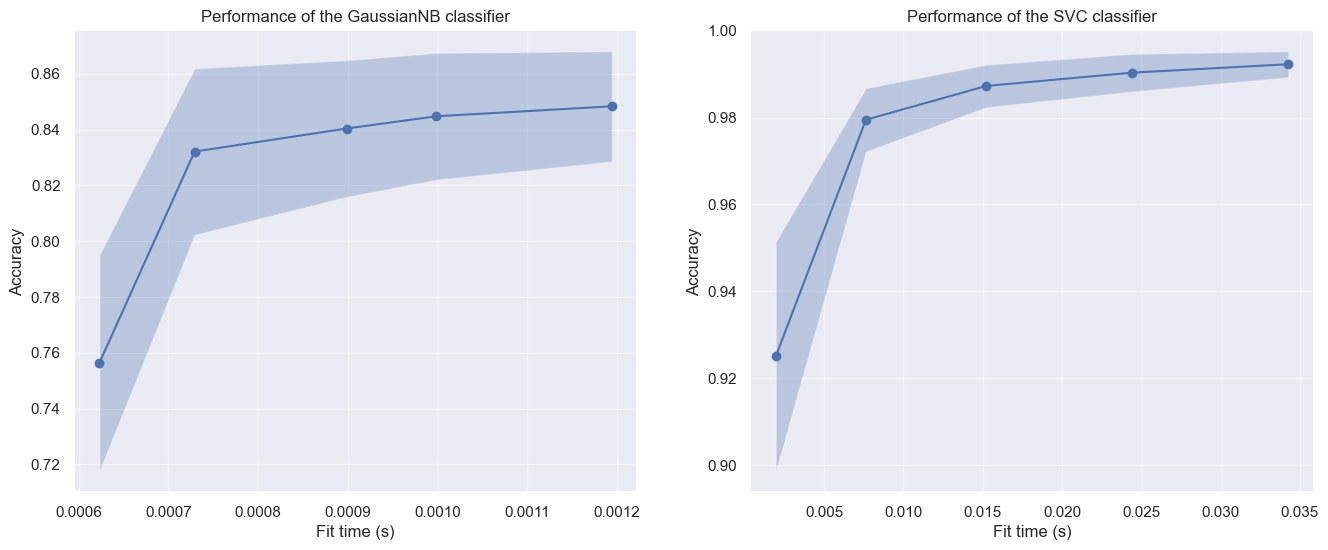

In [22]:
"""
=========================================================
Plotting Learning Curves and Checking Models' Scalability
=========================================================

In this example, we show how to use the class
:class:`~sklearn.model_selection.LearningCurveDisplay` to easily plot learning
curves. In addition, we give an interpretation to the learning curves obtained
for a naive Bayes and SVM classifiers.

Then, we explore and draw some conclusions about the scalability of these predictive
models by looking at their computational cost and not only at their statistical
accuracy.
"""

# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

# %%
# Learning Curve
# ==============
#
# Learning curves show the effect of adding more samples during the training
# process. The effect is depicted by checking the statistical performance of
# the model in terms of training score and testing score.
#
# Here, we compute the learning curve of a naive Bayes classifier and an SVM
# classifier with an RBF kernel using the digits dataset.
from sklearn.datasets import load_digits
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
naive_bayes = GaussianNB()
svc = SVC(kernel="rbf", gamma=0.001)

# %%
# The :meth:`~sklearn.model_selection.LearningCurveDisplay.from_estimator`
# displays the learning curve given the dataset and the predictive model to
# analyze. To get an estimate of the scores uncertainty, this method uses
# a cross-validation procedure.
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import LearningCurveDisplay, ShuffleSplit

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 6), sharey=True)

common_params = {
    "X": X,
    "y": y,
    "train_sizes": np.linspace(0.1, 1.0, 5),
    "cv": ShuffleSplit(n_splits=50, test_size=0.2, random_state=0),
    "score_type": "both",
    "n_jobs": 4,
    "line_kw": {"marker": "o"},
    "std_display_style": "fill_between",
    "score_name": "Accuracy",
}

for ax_idx, estimator in enumerate([naive_bayes, svc]):
    LearningCurveDisplay.from_estimator(estimator, **common_params, ax=ax[ax_idx])
    handles, label = ax[ax_idx].get_legend_handles_labels()
    ax[ax_idx].legend(handles[:2], ["Training Score", "Test Score"])
    ax[ax_idx].set_title(f"Learning Curve for {estimator.__class__.__name__}")

# %%
# We first analyze the learning curve of the naive Bayes classifier. Its shape
# can be found in more complex datasets very often: the training score is very
# high when using few samples for training and decreases when increasing the
# number of samples, whereas the test score is very low at the beginning and
# then increases when adding samples. The training and test scores become more
# realistic when all the samples are used for training.
#
# We see another typical learning curve for the SVM classifier with RBF kernel.
# The training score remains high regardless of the size of the training set.
# On the other hand, the test score increases with the size of the training
# dataset. Indeed, it increases up to a point where it reaches a plateau.
# Observing such a plateau is an indication that it might not be useful to
# acquire new data to train the model since the generalization performance of
# the model will not increase anymore.
#
# Complexity analysis
# ===================
#
# In addition to these learning curves, it is also possible to look at the
# scalability of the predictive models in terms of training and scoring times.
#
# The :class:`~sklearn.model_selection.LearningCurveDisplay` class does not
# provide such information. We need to resort to the
# :func:`~sklearn.model_selection.learning_curve` function instead and make
# the plot manually.

# %%
from sklearn.model_selection import learning_curve

common_params = {
    "X": X,
    "y": y,
    "train_sizes": np.linspace(0.1, 1.0, 5),
    "cv": ShuffleSplit(n_splits=50, test_size=0.2, random_state=0),
    "n_jobs": 4,
    "return_times": True,
}

train_sizes, _, test_scores_nb, fit_times_nb, score_times_nb = learning_curve(
    naive_bayes, **common_params
)
train_sizes, _, test_scores_svm, fit_times_svm, score_times_svm = learning_curve(
    svc, **common_params
)

# %%
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(16, 12), sharex=True)

for ax_idx, (fit_times, score_times, estimator) in enumerate(
    zip(
        [fit_times_nb, fit_times_svm],
        [score_times_nb, score_times_svm],
        [naive_bayes, svc],
    )
):
    # scalability regarding the fit time
    ax[0, ax_idx].plot(train_sizes, fit_times.mean(axis=1), "o-")
    ax[0, ax_idx].fill_between(
        train_sizes,
        fit_times.mean(axis=1) - fit_times.std(axis=1),
        fit_times.mean(axis=1) + fit_times.std(axis=1),
        alpha=0.3,
    )
    ax[0, ax_idx].set_ylabel("Fit time (s)")
    ax[0, ax_idx].set_title(
        f"Scalability of the {estimator.__class__.__name__} classifier"
    )

    # scalability regarding the score time
    ax[1, ax_idx].plot(train_sizes, score_times.mean(axis=1), "o-")
    ax[1, ax_idx].fill_between(
        train_sizes,
        score_times.mean(axis=1) - score_times.std(axis=1),
        score_times.mean(axis=1) + score_times.std(axis=1),
        alpha=0.3,
    )
    ax[1, ax_idx].set_ylabel("Score time (s)")
    ax[1, ax_idx].set_xlabel("Number of training samples")

# %%
# We see that the scalability of the SVM and naive Bayes classifiers is very
# different. The SVM classifier complexity at fit and score time increases
# rapidly with the number of samples. Indeed, it is known that the fit time
# complexity of this classifier is more than quadratic with the number of
# samples which makes it hard to scale to dataset with more than a few
# 10,000 samples. In contrast, the naive Bayes classifier scales much better
# with a lower complexity at fit and score time.
#
# Subsequently, we can check the trade-off between increased training time and
# the cross-validation score.

# %%
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

for ax_idx, (fit_times, test_scores, estimator) in enumerate(
    zip(
        [fit_times_nb, fit_times_svm],
        [test_scores_nb, test_scores_svm],
        [naive_bayes, svc],
    )
):
    ax[ax_idx].plot(fit_times.mean(axis=1), test_scores.mean(axis=1), "o-")
    ax[ax_idx].fill_between(
        fit_times.mean(axis=1),
        test_scores.mean(axis=1) - test_scores.std(axis=1),
        test_scores.mean(axis=1) + test_scores.std(axis=1),
        alpha=0.3,
    )
    ax[ax_idx].set_ylabel("Accuracy")
    ax[ax_idx].set_xlabel("Fit time (s)")
    ax[ax_idx].set_title(
        f"Performance of the {estimator.__class__.__name__} classifier"
    )

plt.show()

# %%
# In these plots, we can look for the inflection point for which the
# cross-validation score does not increase anymore and only the training time
# increases.

(1797, 64)


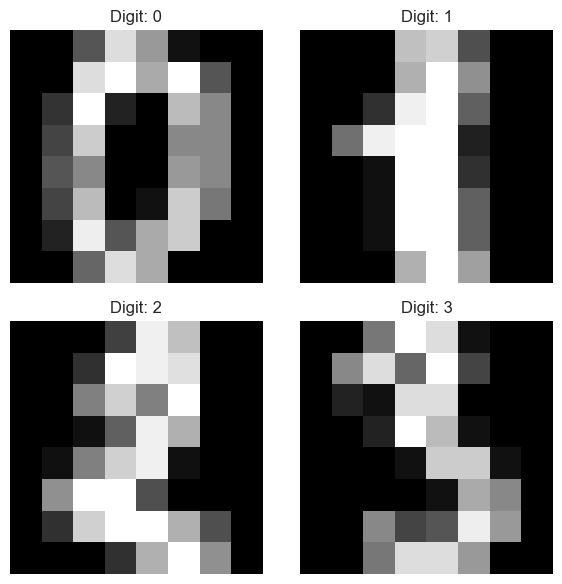

In [23]:
print(X.data.shape)

fig, axes = plt.subplots(2, 2, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(8, 8), cmap="gray")
    ax.set_title(f"Digit: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## The curse of dimensionality

Lastly, I'd like to briefly point out that simply throwing any and all information present at our machine learning algorithm generally isn't the best idea. This is commonly referred to as **the curse of dimensionality, which observes that as the number of features in our dataset grows, the amount of data we need to accurately generalize grows exponentially.**

## Further reading

* [Combining features from different sources](http://scikit-learn.org/stable/auto_examples/hetero_feature_union.html?ref=jeremyjordan.me)
* [How to Handle Missing Data](https://towardsdatascience.com/how-to-handle-missing-data-8646b18db0d4?ref=jeremyjordan.me)
* [Kaggle course on feature engineering](https://www.kaggle.com/learn/feature-engineering?ref=jeremyjordan.me)